# DeepEpilepsy на турецком наборе ЭЭГ без обучения

| Поле | Значение |
|------|----------|
| **Автор** | Захар Санников (zs) |
| **Дата** | 2026-10-18 |
| **Гипотеза** | Г1 (ЭЭГ) |
| **Цель** | Проверить готовую модель DeepEpilepsy **без какого-либо обучения на наших данных** — честная проверка переноса: модели не на чем выучить перекосы этого набора |
| **Данные** | Turkish Epilepsy EEG Dataset (Kaggle `buraktaci/turkish-epilepsy`): 50 эпилепсия + 71 норма (здоровые), 500 Гц, куски по 15 с |
| **Модель** | DeepEpilepsy (Lemoine et al., Brain Communications 2025, doi 10.1093/braincomms/fcaf319): ViT1d со свёрточным токенизатором, Large, окна 30 с, 200 Гц, 19 каналов. Веса: HF `emilelemoine/DeepEpilepsy_v1`, MIT. Обучена на 820 рутинных ЭЭГ клиники CHUM (Монреаль); у авторов на тесте ROC AUC 0,76 |
| **Деление обучение/тест** | Обучения нет — весь набор служит тестом |
| **Среда** | Kaggle, GPU T4, интернет включён, набор подключён через Add Input |
| **Журнал** | строка в `experiments_log.md`: добавить |

**Важно:** на Hugging Face рабочий только файл `DeepEpilepsy_large_50_30s_augment.pt`; три других файла (10 с и Small) — пустые ссылки-заглушки (~130 байт). Поэтому используем окна по 30 с.

Сравнение: `h1_2026-10-18_zs_reve-turkish.ipynb` (там одна амплитуда сигнала давала ROC AUC 0,79).

## 1. Код и веса модели

In [7]:
import os, sys, subprocess, importlib.util, torch
from huggingface_hub import hf_hub_download

REPO = "/kaggle/working/dl_epilepsy_reeg"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "--depth", "1", "https://gitlab.com/chum-epilepsy/dl_epilepsy_reeg.git", REPO], check=True)

# берём только файл с архитектурой, без остального пакета авторов
spec = importlib.util.spec_from_file_location("de_transformers", f"{REPO}/src/epileptology/ml/models/transformers.py")
de = importlib.util.module_from_spec(spec); spec.loader.exec_module(de)

SFREQ, SEG = 200, 30
# параметры ViT1d_Conv1d_large_50 из models_config.yaml авторов
model = de.ViT1d(n_class=2, in_channels=19, n_timepoints=SFREQ * SEG, patch_size=50, tokenizer="conv1d",
                 n_layers=6, n_heads=8, dim_hidden=512, dim_mlp=512, dropout=0.25, attention_dropout=0.25)
w = hf_hub_download("emilelemoine/DeepEpilepsy_v1", "DeepEpilepsy_large_50_30s_augment.pt")
model.load_state_dict(torch.load(w, map_location="cpu", weights_only=True), strict=True)
model = model.eval().cuda()
with torch.no_grad():
    print("проверка на шуме:", torch.softmax(model(torch.randn(2, 19, SFREQ * SEG).cuda()), 1).cpu().numpy().round(3))
print("GPU:", torch.cuda.get_device_name(0))

проверка на шуме: [[0.504 0.496]
 [0.728 0.272]]
GPU: Tesla T4


## 2. Данные и подготовка

- Каналы — в порядке, как у авторов (`settings.ELECTRODES`): Fp1, Fp2, F3, F4, C3, C4, P3, P4, F7, F8, T3, T4, T5, T6, O1, O2, Fz, Cz, Pz. В турецком наборе это первые 19 каналов (относительно уха), переставленные в нужный порядок.
- Фильтр 0,5–70 Гц + режекция 50 Гц (сеть в Турции 50 Гц, в Канаде 60), 500 → 200 Гц.
- Окно 30 с = **два соседних куска по 15 с**. Сначала проверяем, идут ли куски в файле подряд (нет ли скачка на стыке).
- Нормировка каждого канала в окне (как `standard_scale` у авторов), вероятность эпилепсии = softmax.
- Оценка человека = **медиана** по окнам (так у авторов, `AggAUROC(agg_fun="median")`), дополнительно — среднее.

In [8]:
import glob, numpy as np, scipy.io, scipy.signal as ss

ROOT = glob.glob("/kaggle/input/**/Turkish Epilepsy Dataset", recursive=True)[0]
files = [(f, 1) for f in sorted(glob.glob(f"{ROOT}/epilepsy/*.mat"))] + \
        [(f, 0) for f in sorted(glob.glob(f"{ROOT}/normal/*.mat"))]
print("файлов:", len(files))

# индексы турецких каналов в порядке модели:      Fp1 Fp2 F3 F4 C3 C4 P3 P4 F7  F8  T3  T4  T5  T6  O1  O2  Fz Cz Pz
IDX = [0, 1, 2, 3, 5, 6, 8, 9, 13, 14, 15, 16, 17, 18, 11, 12, 4, 7, 10]

def load_pieces(f):
    d = scipy.io.loadmat(f)["data"]
    return np.stack([np.stack([d[s, c].ravel() for c in IDX]) for s in range(d.shape[0])])  # (куски, 19, 7500)

# проверка: идут ли куски подряд? скачок на стыке против обычного шага внутри куска
for f, y in files[:3] + files[-3:]:
    X = load_pieces(f)
    inner = np.median(np.abs(np.diff(X, axis=-1)))
    joint = np.median(np.abs(X[1:, :, 0] - X[:-1, :, -1]))
    print(f"{os.path.basename(f):28s} обычный шаг {inner:7.2f} | скачок на стыке {joint:7.2f} | отношение {joint/inner:5.1f}")

файлов: 121
1_epilepsy (1).mat           обычный шаг    1.70 | скачок на стыке    1.74 | отношение   1.0
1_epilepsy (10).mat          обычный шаг    1.93 | скачок на стыке    1.57 | отношение   0.8
1_epilepsy (11).mat          обычный шаг    0.43 | скачок на стыке    0.43 | отношение   1.0
2_Normal (71).mat            обычный шаг    1.02 | скачок на стыке    0.90 | отношение   0.9
2_Normal (8).mat             обычный шаг    0.62 | скачок на стыке    0.59 | отношение   0.9
2_Normal (9).mat             обычный шаг    0.39 | скачок на стыке    0.39 | отношение   1.0


Если отношение около 1–3 — куски идут подряд и склейка двух кусков = настоящие 30 с. Если десятки и больше — куски не соседние, на стыке будет ступенька (оговорка в выводах).

In [9]:
import time
SOS = ss.butter(4, [0.5, 70], btype="band", fs=500, output="sos")
bn, an = ss.iirnotch(50, 30, fs=500)

def scale(x):
    return (x - x.mean(-1, keepdims=True)) / (x.std(-1, keepdims=True) + 1e-20)

res = []
t0 = time.time()
for i, (f, y) in enumerate(files):
    X = load_pieces(f)
    X = ss.filtfilt(bn, an, ss.sosfiltfilt(SOS, X, axis=-1), axis=-1)
    X = ss.resample_poly(X, 2, 5, axis=-1)                      # (куски, 19, 3000) = 15 с при 200 Гц
    n = len(X) // 2
    W = np.concatenate([X[0:2*n:2], X[1:2*n:2]], axis=-1)      # (окна, 19, 6000) = 30 с
    W = scale(W)
    p = []
    with torch.no_grad():
        for b in range(0, len(W), 32):
            x = torch.tensor(W[b:b+32], dtype=torch.float32).cuda()
            p.append(torch.softmax(model(x), 1)[:, 1].cpu().numpy())
    p = np.concatenate(p)
    res.append(dict(file=os.path.basename(f), y=y, n_win=len(p), median=np.median(p), mean=p.mean(), probs=p))
    if (i + 1) % 10 == 0 or i + 1 == len(files):
        print(f"{i+1}/{len(files)} {time.time()-t0:.0f} с")

import pandas as pd
df = pd.DataFrame(res)
df.drop(columns="probs").to_csv("/kaggle/working/deepepilepsy_turkish_scores.csv", index=False)
print(df.groupby("y")[["n_win", "median", "mean"]].median())

10/121 26 с
20/121 55 с
30/121 76 с
40/121 117 с
50/121 148 с
60/121 181 с
70/121 208 с
80/121 234 с
90/121 260 с
100/121 284 с
110/121 310 с
120/121 335 с
121/121 337 с
   n_win    median      mean
y                           
0   37.0  0.005877  0.045971
1   36.0  0.002337  0.015880


## 3. Метрики (уровень человека, без обучения)

DeepEpilepsy, median по окнам: ROC AUC = 0.378  (95% ДИ 0.28–0.49)
DeepEpilepsy, mean   по окнам: ROC AUC = 0.351  (95% ДИ 0.25–0.45)
доля «эпилептических» окон: эпилепсия 0.00, норма 0.03


/tmp/ipykernel_49/781788035.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([df["median"][y == 0], df["median"][y == 1]], labels=["норма", "эпилепсия"])


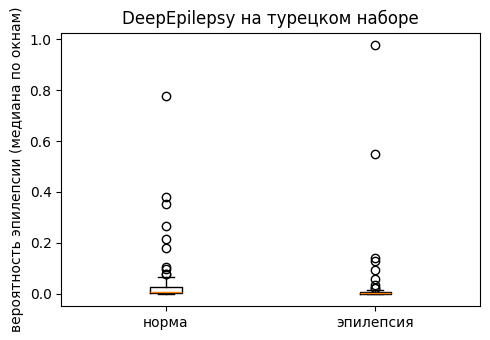

In [10]:
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

def boot_ci(yt, s, n=2000, seed=0):
    rng = np.random.default_rng(seed); v = []
    for _ in range(n):
        i = rng.integers(0, len(yt), len(yt))
        if len(set(yt[i])) == 2: v.append(roc_auc_score(yt[i], s[i]))
    return np.percentile(v, [2.5, 97.5])

y = df.y.to_numpy()
for agg in ["median", "mean"]:
    s = df[agg].to_numpy()
    lo, hi = boot_ci(y, s)
    print(f"DeepEpilepsy, {agg:6s} по окнам: ROC AUC = {roc_auc_score(y, s):.3f}  (95% ДИ {lo:.2f}–{hi:.2f})")

# доля окон с вероятностью > 0,5
df["share"] = df.probs.map(lambda p: (p > 0.5).mean())
print(f"доля «эпилептических» окон: эпилепсия {df.share[y==1].median():.2f}, норма {df.share[y==0].median():.2f}")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.boxplot([df["median"][y == 0], df["median"][y == 1]], labels=["норма", "эпилепсия"])
ax.set_ylabel("вероятность эпилепсии (медиана по окнам)")
ax.set_title("DeepEpilepsy на турецком наборе")
plt.tight_layout(); plt.savefig("/kaggle/working/deepepilepsy_turkish.png", dpi=100); plt.show()

### 3.1. Проверка: может, дело в подготовке сигнала?

Четыре варианта: без фильтра / фильтр 1–70 Гц + режекция 50 Гц; референт — ухо (как в наборе) / средний. Данные читаются один раз (200 Гц).

In [ ]:
from sklearn.metrics import roc_auc_score
import time

def scale(x):
    return (x - x.mean(-1, keepdims=True)) / (x.std(-1, keepdims=True) + 1e-20)

CACHE, t0 = [], time.time()
for i, (f, yy) in enumerate(files):
    X = ss.resample_poly(load_pieces(f), 2, 5, axis=-1).astype(np.float32)   # 200 Гц, без фильтра
    CACHE.append((X, yy))
    if (i + 1) % 10 == 0 or i + 1 == len(files):
        print(f"прочитано {i+1}/{len(files)}, {time.time()-t0:.0f} с", flush=True)

SOS200 = ss.butter(4, [1, 70], btype="band", fs=200, output="sos")
b50, a50 = ss.iirnotch(50, 30, fs=200)
VARIANTS = {
    "без фильтра, ухо":              lambda X: X,
    "без фильтра, средний референт": lambda X: X - X.mean(1, keepdims=True),
    "1–70 Гц + 50 Гц, ухо":          lambda X: ss.filtfilt(b50, a50, ss.sosfiltfilt(SOS200, X, axis=-1), axis=-1),
    "1–70 Гц + 50 Гц, средний реф.": lambda X: ss.filtfilt(b50, a50, ss.sosfiltfilt(SOS200, X - X.mean(1, keepdims=True), axis=-1), axis=-1),
}
for name, prep in VARIANTS.items():
    med, yv = [], []
    for X, yy in CACHE:
        Xp = prep(X.astype(np.float64)); n = len(Xp) // 2
        W = scale(np.concatenate([Xp[0:2*n:2], Xp[1:2*n:2]], axis=-1))
        with torch.no_grad():
            p = np.concatenate([torch.softmax(model(torch.tensor(W[b:b+32], dtype=torch.float32).cuda()), 1)[:, 1].cpu().numpy()
                                for b in range(0, len(W), 32)])
        med.append(np.median(p)); yv.append(yy)
    med, yv = np.array(med), np.array(yv)
    print(f"{name:32s} ROC AUC = {roc_auc_score(yv, med):.3f} | медиана вероятности: норма {np.median(med[yv==0]):.3f}, эпилепсия {np.median(med[yv==1]):.3f}", flush=True)

прочитано 121/121, 289 с
без фильтра, ухо                 ROC AUC = 0.381 | медиана вероятности: норма 0.008, эпилепсия 0.004
без фильтра, средний референт    ROC AUC = 0.565 | медиана вероятности: норма 0.000, эпилепсия 0.000
1–70 Гц + 50 Гц, ухо             ROC AUC = 0.376 | медиана вероятности: норма 0.004, эпилепсия 0.002
1–70 Гц + 50 Гц, средний реф.    ROC AUC = 0.531 | медиана вероятности: норма 0.000, эпилепсия 0.000

## 4. Выводы

| Подготовка сигнала | ROC AUC | Медиана вероятности (норма / эпилепсия) |
|---|---|---|
| 0,5–70 Гц + 50 Гц, ухо (основной прогон) | 0,38 (95% ДИ 0,28–0,49) | 0,006 / 0,002 |
| без фильтра, ухо | 0,38 | 0,008 / 0,004 |
| без фильтра, средний референт | 0,57 | 0,000 / 0,000 |
| 1–70 Гц + 50 Гц, ухо | 0,38 | 0,004 / 0,002 |
| 1–70 Гц + 50 Гц, средний референт | 0,53 | 0,000 / 0,000 |

1. **Готовая DeepEpilepsy на турецком наборе не работает**: при любой подготовке ROC AUC 0,38–0,57, т. е. на уровне угадывания или хуже.
2. **Модель считает «не эпилепсия» почти всех**: вероятности близки к нулю у обеих групп. Записи для неё слишком непохожи на те, на которых её обучали (другая клиника, аппарат, референт, страна; контроль — здоровые).
3. **Подготовка сигнала не спасает**: фильтр и референт меняют цифры в пределах шума.
4. Куски по 15 с идут подряд (скачок на стыке ≈ обычному шагу), склейка в окна по 30 с корректна.
5. **Главный вывод для проекта:** модель, обученная в одной клинике, **без дообучения не переносится** в другую. Это прямо подтверждает, что в MVP нужна подстройка (дообучение) под данные конкретной клиники и проверка переносом. У авторов 0,76 — на их же клинике.

**Ограничения:** контроль — здоровые (у авторов — пациенты клиники); другой аппарат и референт (ухо), сеть 50 Гц; модель обучена на пациентах одной канадской клиники; используется только вариант Large 30 с (остальные веса на HF не выложены); точная подготовка сигнала у авторов (референт, аппаратные фильтры) неизвестна.

## 5. Что дальше

- Готовую DeepEpilepsy как есть дальше не проверяем.
- Её архитектуру (или веса как стартовую точку) можно **дообучить** на TUEP — сравнить с REVE и простыми мощностями ритмов.